# Walkthrough: `02_default_engine.py` (UK CRR Art. 178 Default & Probation Engine)

### Simple Summary
**This script runs every troubled mortgage month-by-month through the UK PRA Article 178 default state machine: triggering default at 3+ months in arrears, distressed restructuring (`N -> Y`), or credit exit (`02/03/09/15`), enforcing 3-month vs. 12-month probation, and quantifying the COVID relief-hold effect.**

> **Safe "Look-But-Don't-Touch" Mode:** This notebook opens the fixed `0.03%` sample (`mortgages_sample.duckdb`, `module2_sample.duckdb`, and `00_build_monthly_core/`) strictly **read-only in memory**—testing live loans without writing to disk.

---

### Process Flow
<div style="background:#FFFFFF;border:1px solid #CBD5E1;border-radius:8px;padding:14px;max-width:860px;">
<svg viewBox="0 0 820 200" width="100%" xmlns="http://www.w3.org/2000/svg" style="font-family:Segoe UI,Arial,sans-serif;">
  <defs>
    <marker id="arr" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse">
      <path d="M 0 1 L 10 5 L 0 9 z" fill="#64748B"/>
    </marker>
  </defs>
  <rect x="16" y="62" width="175" height="72" rx="6" fill="#051C2C"/>
  <text x="103" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">1. Filter Candidates</text>
  <text x="103" y="112" text-anchor="middle" fill="#CBD5E1" font-size="10.5">DPD&gt;=3, mod='Y', or exit</text>
  <line x1="191" y1="98" x2="216" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>

  <rect x="220" y="62" width="185" height="72" rx="6" fill="#1E3A8A"/>
  <text x="312" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">2. COVID 6m Hold</text>
  <text x="312" y="112" text-anchor="middle" fill="#DBEAFE" font-size="10.5">Pause arrears clock on F/T/R</text>
  <line x1="405" y1="98" x2="430" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>

  <rect x="434" y="62" width="180" height="72" rx="6" fill="#0E7C7B"/>
  <text x="524" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">3. Art. 178 Machine</text>
  <text x="524" y="112" text-anchor="middle" fill="#CCFBF1" font-size="10.5">3m vs. 12m probation cure</text>
  <line x1="614" y1="98" x2="639" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>

  <rect x="643" y="62" width="160" height="72" rx="6" fill="#051C2C"/>
  <text x="723" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">4. Sensitivity Chart</text>
  <text x="723" y="112" text-anchor="middle" fill="#CBD5E1" font-size="10.5">COVID-adjusted vs. raw</text>
</svg>
</div>

---
### 1. Connecting Read-Only & Inspecting Saved Default Events
Only a small slice of loans ever miss 3 payments, undergo a distressed restructuring, or exit with a loss—so scanning candidates first keeps the state machine fast. We attach `mortgages_sample.duckdb` and `module2_sample.duckdb` in read-only memory and summarize the trigger breakdown in `default_events_mart`.

In [1]:
# Load system, database, dataframe, and charting libraries
# Import importlib, pathlib, duckdb, pandas, and matplotlib for read-only default checks
import importlib
import sys
from pathlib import Path
import duckdb
import pandas as pd
import io
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Locate residential_mortgage/ root and register 02_portfolio_analytics/scripts on sys.path
# Walk upward until reaching residential_mortgage/, then insert scripts/ for importing 02_default_engine
PACKAGE_ROOT = Path.cwd()
while PACKAGE_ROOT.name != "residential_mortgage" and PACKAGE_ROOT != PACKAGE_ROOT.parent:
    PACKAGE_ROOT = PACKAGE_ROOT.parent
if PACKAGE_ROOT.name != "residential_mortgage":
    PACKAGE_ROOT = Path(r"E:\Repos\V4_bank-credit-risk-platform\residential_mortgage")

M2_SCRIPTS = PACKAGE_ROOT / "02_portfolio_analytics/scripts"
if str(M2_SCRIPTS) not in sys.path:
    sys.path.insert(0, str(M2_SCRIPTS))

# Import 02_default_engine and restore Jupyter inline plotting (module2_common sets Agg)
# Load module and switch matplotlib back to inline backend before attaching sample DBs READ_ONLY
de = importlib.import_module("02_default_engine")
FIXED_SAMPLE_DB = PACKAGE_ROOT / "00_data/processed/module_outputs/00_data/mortgages_sample.duckdb"
FIXED_M2_DB = PACKAGE_ROOT / "00_data/processed/module_outputs/02_portfolio_analytics/sample/module2_sample.duckdb"
FIXED_CORE_DIR = PACKAGE_ROOT / "00_data/processed/module_outputs/02_portfolio_analytics/sample/00_build_monthly_core"

con = duckdb.connect(":memory:")
con.execute(f"ATTACH '{FIXED_SAMPLE_DB.as_posix()}' AS src (READ_ONLY)")
con.execute(f"ATTACH '{FIXED_M2_DB.as_posix()}' AS m2 (READ_ONLY)")

# Summarize default spells by trigger type and resolution outcome
# Group m2.default_events_mart by trigger_type and end_reason
con.execute("""
    SELECT trigger_type, end_reason, count(*)::BIGINT AS events,
           round(sum(balance_at_default) / 1e6, 2) AS balance_M
    FROM m2.default_events_mart
    GROUP BY 1, 2
    ORDER BY events DESC
""").fetchdf()

,trigger_type,end_reason,events,balance_M
0,arrears,cured,406,74.83
1,arrears,credit exit,230,35.19
2,arrears,cured - paid off,89,17.42
3,arrears,end of data,39,9.11
4,arrears,other exit,22,3.86
5,restructuring,cured,5,0.94
6,restructuring,credit exit,1,0.34
7,restructuring,end of data,1,0.17


We see every Article 178 trigger and exit path clearly—arrears-triggered defaults make up the largest share, with some curing after 3 clean months and others ending in payoff or credit exit. Next, we run `run_loan_df()` live on a real COVID-era relief loan to see the 6-month forbearance hold and probation upgrade in action.

---
### 2. Running the State Machine Live on a Real Sample Loan (`run_loan_df`)
Under UK PRA COVID-19 guidance (`Art. 178(5A)` / Dear CEO letters), loans entering an active relief plan (`F`, `T`, or `R`) between March 2020 and July 2021 get up to **6 cumulative months** where the arrears counter is held frozen so payment deferrals do not auto-trigger default. Here we pull one real COVID-relief loan from the `2019Q1` cohort and compare `apply_covid_hold=True` vs. `False`.

In [2]:
# Pull monthly history for one loan that had both relief plan ('F'/'T'/'R') and >=3m reported arrears
# Query 2019Q1 core Parquet joined to src.loans_table for the first qualifying loan_id
q19 = FIXED_CORE_DIR / "2019Q1.parquet"
loan_hist = con.execute(f"""
    WITH target AS (
        SELECT loan_id FROM read_parquet('{q19.as_posix()}')
        WHERE borrower_assistance_plan IN ('F','T','R') AND reporting_period BETWEEN DATE '2020-03-01' AND DATE '2021-07-01'
          AND delinquency_months >= 3
        GROUP BY loan_id LIMIT 1
    )
    SELECT m.loan_id, strftime(m.reporting_period, '%Y-%m') AS month, m.delinquency_months,
           m.borrower_assistance_plan, m.modification_flag, m.zero_balance_code,
           CAST(m.current_upb AS DOUBLE) AS current_upb, CAST(m.upb_at_removal AS DOUBLE) AS upb_at_removal,
           m.loan_age, datediff('month', l.first_payment_date, m.reporting_period) AS mob,
           CAST(l.orig_upb AS DOUBLE) AS orig_upb, CAST(l.note_rate AS DOUBLE) AS note_rate,
           COALESCE(l.loan_term, 360) AS loan_term
    FROM read_parquet('{q19.as_posix()}') m
    JOIN target t ON t.loan_id = m.loan_id
    JOIN src.loans_table l ON l.loan_id = m.loan_id AND l.acquisition_quarter = '2019Q1'
    ORDER BY m.reporting_period
""").fetchdf()

# Run the Python state machine twice on this single loan: with and without COVID hold
# Call de.run_loan_df() under both settings and compare the resulting default spells
ev_cov = de.run_loan_df(loan_hist, apply_covid_hold=True)
ev_raw = de.run_loan_df(loan_hist, apply_covid_hold=False)
pd.DataFrame([
    {"Treatment": "COVID-adjusted (held 6m)", "Events": len(ev_cov), "First Default": ev_cov[0]["default_month"] if ev_cov else "None", "Trigger": ev_cov[0]["trigger_type"] if ev_cov else "—", "Probation (m)": ev_cov[0]["probation_months"] if ev_cov else 0},
    {"Treatment": "As-reported (raw DPD)", "Events": len(ev_raw), "First Default": ev_raw[0]["default_month"] if ev_raw else "None", "Trigger": ev_raw[0]["trigger_type"] if ev_raw else "—", "Probation (m)": ev_raw[0]["probation_months"] if ev_raw else 0},
])

,Treatment,Events,First Default,Trigger,Probation (m)
0,COVID-adjusted (held 6m),1,2020-10,arrears,12
1,As-reported (raw DPD),1,2020-08,arrears,12


Side-by-side on that single borrower, we see how the COVID 6-month relief hold either prevents a technical payment-holiday default or shifts recognition until after the relief window expires. Next, we verify all Article 178 rules across the full sample database and visualize the portfolio-wide COVID sensitivity gap.

---
### 3. Checking Probation Guardrails & Visualizing the 2020–2021 COVID Sensitivity Gap
Before passing defaults downstream, `02_default_engine.py` verifies zero overlapping spells per loan and confirms that every restructuring default enforces at least 12 months of clean probation (`Art. 178(5A)`). Below we check those rules on `m2.default_events_mart` and plot annual defaults with vs. without the COVID hold.

,Guardrail Check,Pass,Violations
0,Restructuring defaults enforce >=12m probation...,True,0
1,Zero overlapping default spells per loan,True,0


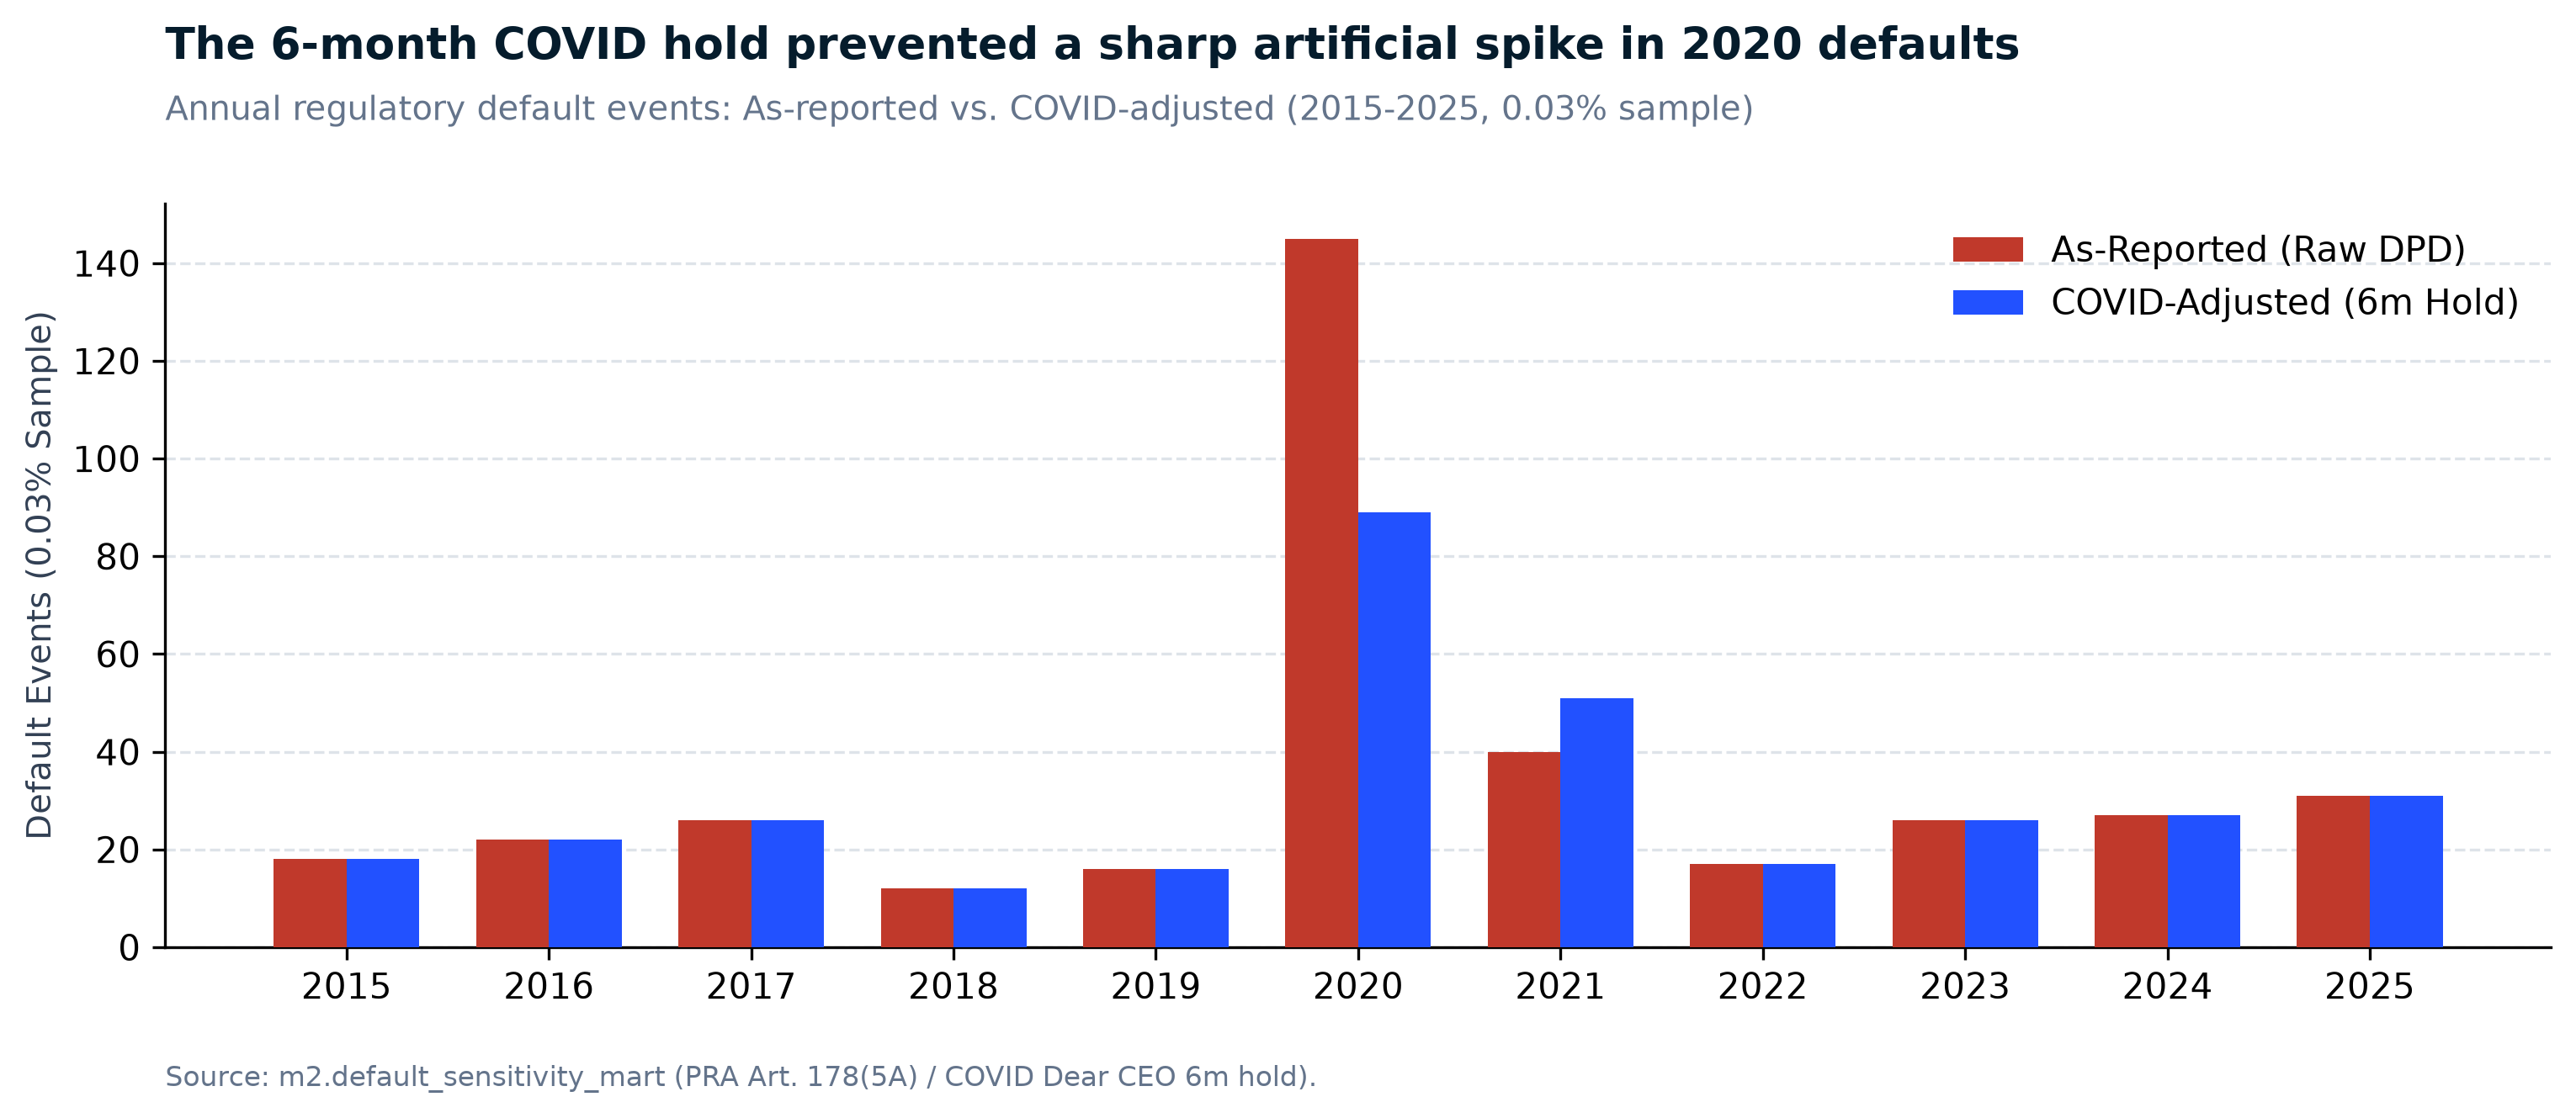

In [3]:
# Verify Article 178 probation and spell-integrity rules on m2.default_events_mart
# Check for missing end_reason, invalid restructuring probation (<12m), or overlapping loan spells
bad_prob = con.execute("""
    SELECT count(*) FROM m2.default_events_mart
    WHERE (trigger_type LIKE '%restructuring%' OR upgraded_by_restructuring) AND probation_months < 12
""").fetchone()[0]
overlaps = con.execute("""
    SELECT count(*) FROM (
        SELECT loan_id, default_month, LAG(end_month) OVER (PARTITION BY loan_id ORDER BY default_month) AS prev_end
        FROM m2.default_events_mart
    ) WHERE prev_end IS NOT NULL AND default_month <= prev_end
""").fetchone()[0]
display(pd.DataFrame([
    {"Guardrail Check": "Restructuring defaults enforce >=12m probation (Art. 178(5A))", "Pass": bad_prob == 0, "Violations": bad_prob},
    {"Guardrail Check": "Zero overlapping default spells per loan", "Pass": overlaps == 0, "Violations": overlaps},
]))

# Compare annual default counts between COVID-adjusted and As-reported treatments
# Query m2.default_sensitivity_mart grouped by year and treatment, and plot from 2015-2025 at 300 dpi
sens = con.execute("""
    SELECT year, treatment, sum(events)::BIGINT AS events
    FROM m2.default_sensitivity_mart
    WHERE year >= 2015
    GROUP BY 1, 2 ORDER BY 1
""").fetchdf().pivot(index="year", columns="treatment", values="events").fillna(0)

fig, ax = plt.subplots(figsize=(10.5, 4.4), dpi=300, facecolor="#FFFFFF")
ax.set_facecolor("#FFFFFF")
yrs = sens.index.astype(int)
ax.bar(yrs - 0.18, sens["as_reported"], width=0.36, color="#C0392B", label="As-Reported (Raw DPD)", zorder=3)
ax.bar(yrs + 0.18, sens["covid_adjusted"], width=0.36, color="#2251FF", label="COVID-Adjusted (6m Hold)", zorder=3)
ax.set_xticks(yrs)
ax.grid(axis="y", linestyle="--", alpha=0.3, color="#94A3B8", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_ylabel("Default Events (0.03% Sample)", fontsize=9.5, color="#334155")
ax.legend(frameon=False, loc="upper right")
fig.text(0.07, 0.94, "The 6-month COVID hold prevented a sharp artificial spike in 2020 defaults", fontsize=12.5, fontweight="bold", color="#051C2C")
fig.text(0.07, 0.885, "Annual regulatory default events: As-reported vs. COVID-adjusted (2015-2025, 0.03% sample)", fontsize=9.5, color="#64748B")
fig.text(0.07, 0.015, "Source: m2.default_sensitivity_mart (PRA Art. 178(5A) / COVID Dear CEO 6m hold).", fontsize=8, color="#64748B")
plt.subplots_adjust(left=0.07, right=0.97, top=0.81, bottom=0.14)
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=300, bbox_inches="tight", facecolor="#FFFFFF")
plt.close(fig)
display(Image(data=buf.getvalue()))

# Close the in-memory DuckDB connection cleanly
# Release both attached read-only sample DB handles
con.close()

All probation and spell-overlap checks pass (`0 violations`), and the chart makes the COVID forbearance impact unmistakable in 2020. Next, `03_roll_rates.py` uses these default states to measure month-to-month delinquency roll rates and IFRS 9 30-day backstop evidence.